In [118]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [119]:
k_dfs = [pd.read_csv(f"k_big/{fname}") for fname in os.listdir("k_big")] + [pd.read_csv(f"k1-20/{fname}") for fname in os.listdir("k1-20")]

In [120]:
k_df = pd.concat(k_dfs).sort_values(["problem_name"])
k_df["suite"] = k_df["problem_name"].apply(lambda x: x.split("-")[0])
k_df

,problem_name,vars,clauses,decision_type,num_threads,num_nodes,duration_mus,suite
2905,uf100-01.cnf,100,430,MOMS_1,12,113,3621,uf100
2905,uf100-01.cnf,100,430,MOMS_15,12,129,4141,uf100
2905,uf100-01.cnf,100,430,MOMS_5,12,205,5111,uf100
2905,uf100-01.cnf,100,430,MOMS_2,12,129,3642,uf100
2905,uf100-01.cnf,100,430,MOMS_4,12,133,3703,uf100
...,...,...,...,...,...,...,...,...
2013,uf75-099.cnf,75,325,MOMS_3,12,285,3387,uf75
2013,uf75-099.cnf,75,325,MOMS_10,12,279,3501,uf75
2013,uf75-099.cnf,75,325,MOMS_1,12,307,3642,uf75
2013,uf75-099.cnf,75,325,MOMS_15,12,276,3421,uf75


In [121]:
avgs = {}

for suite in k_df["suite"].unique():
    avgs[suite] = dict()
    for k in k_df["decision_type"].unique():
        avgs[suite][int(k.split("_")[1])] = k_df[(k_df["suite"] == suite) & (k_df["decision_type"] == k)]["duration_mus"].mean()

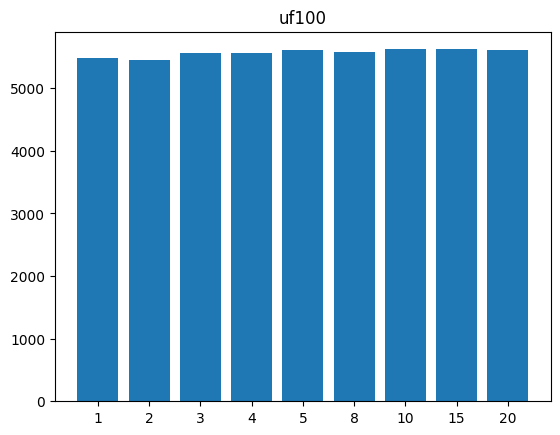

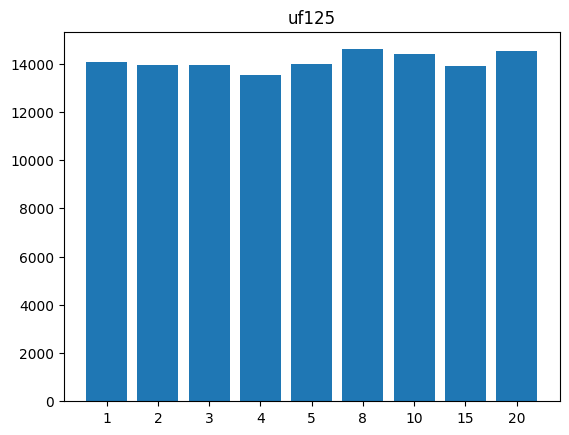

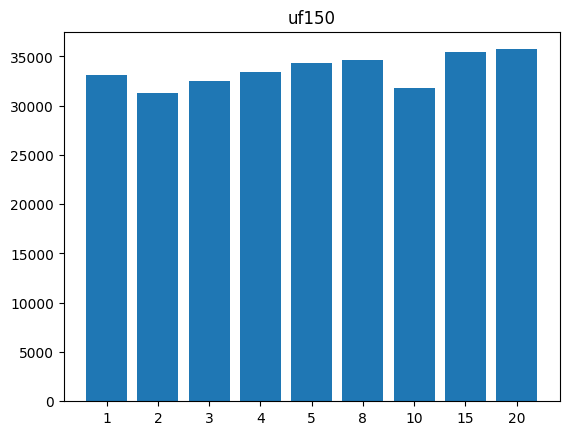

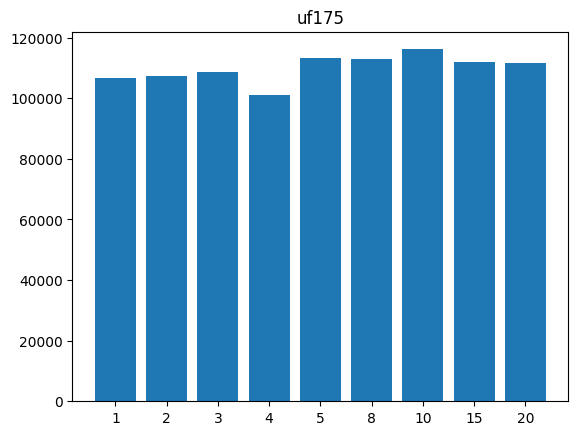

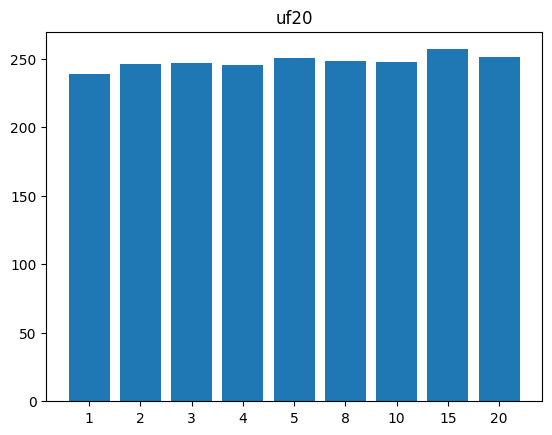

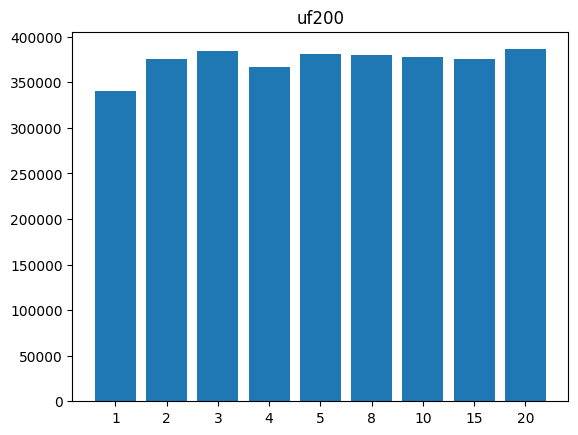

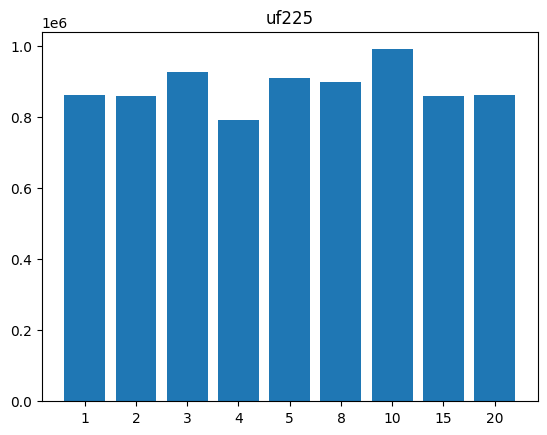

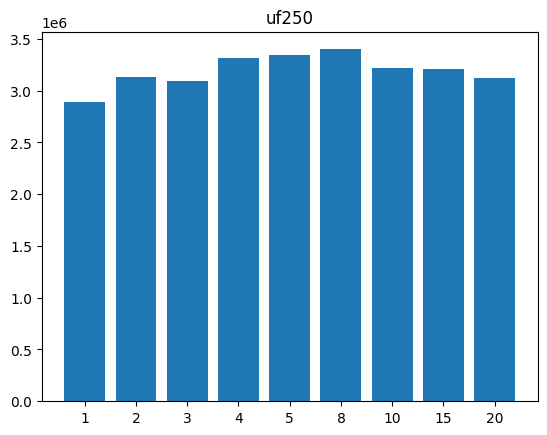

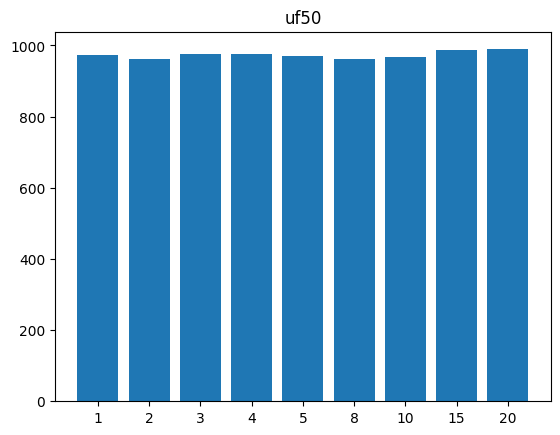

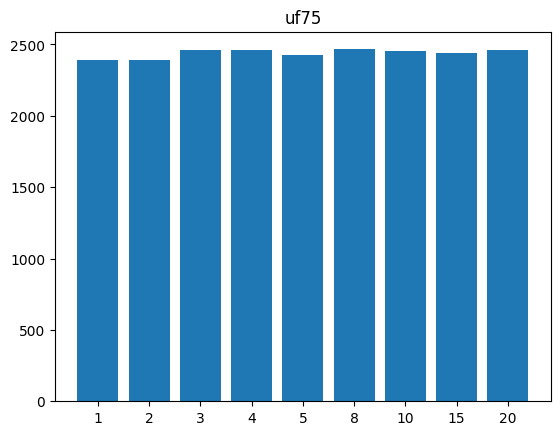

In [122]:
for suite in k_df["suite"].unique():
    tups = [(k, avgs[suite][k]) for k in sorted(avgs[suite].keys())]
    
    plt.bar(range(len(avgs[suite])), [item[1] for item in tups])
    plt.xticks(range(len(avgs[suite])), [item[0] for item in tups])
    plt.title(suite)
    plt.show()